In [54]:
import numpy as np
import matplotlib.pyplot as plt

In [55]:
# Unidades

## Comprimento
um = 1e-6
nm = 1e-9

## Frequência

GHz = 1e9
THz = 1e12

## Tempo

ns = 1e-9
ps = 1e-12

# Constantes

pi = np.pi
c = 3e8 # m/s
lambda0 = 1.55*um
f0 = c/lambda0

## Parametros do guia de onda

w = 500*nm
h = 220*nm

neff = 2.4455
ng = 4.1909

# Mapas de cores

cmap1 = plt.cm.viridis
cmap2 = plt.cm.plasma
cmap3 = plt.cm.inferno
cmap4 = plt.cm.magma
cmap5 = plt.cm.coolwarm
cmap6 = plt.cm.turbo
cmap7 = plt.cm.GnBu
cmap8 = plt.cm.winter

### Anel add-drop ###

In [56]:
def neff_lambda(lambda_, n_eff = neff, n_g = ng):
    neff_ = n_g + lambda_*(n_eff-n_g)/lambda0
    return neff_

def phi(lambda_, L, n_eff=neff):
    num = 2*pi*neff_lambda(lambda_, n_eff)*L
    den = lambda_
    return num/den

def T_p(phi,r1,r2,a):
    num = r1**2 - 2*r1*r2*a*np.cos(phi) + (r2*a)**2
    den = 1 - 2*r1*r2*a*np.cos(phi) + (r1*r2*a)**2
    return num/den

def T_d(phi,r1,r2,a):
    num = (1 - r1**2)*(1 - r2**2)*a
    den = 1 - 2*r1*r2*a*np.cos(phi) + (r1*r2*a)**2
    return num/den

# Questões #

1) **Projeto 1 com acoplamento crítico**. Imponha $r_1=r_2a$ mantendo $FWHM=5\,GHz$. Quais os novos $k^2_1$, $k^2_2$, $T_{d,max}$ e extinção no throught?

2) **Perda**. Para $FSR=100\,GHz$ e $FWHM=2\,GHz$, qual a perda de propagação máxima que garantre $T_{d,max}>-3\,dB$?

3) **Racetrack $\times$ Circular**. No projeto 1, troque o acoplador reto por um halfring com $L_c=0$ e $R=114\,\mu m$. Estime o gap pelo modelo $\kappa^2(g,R)$. A extrapolação é confiável? (Resposta em outro arquivo)

4) **Vernier**. Refaça o porjeto 2 com $N_1=5$, $N_2=6$. Qual $FWHM$ mantem a supressão em $-25\,dB$? Qual o custo em $Q$?

## Resposta da 1 ##

$$r_1=0,8548\rightarrow k^2_1=0,2693\,;$$

$$r_2=0,8762\rightarrow k^2_2=0,2323\;$$

$$T_{d,max}\approx 0,8415,;$$

$$EX=-\infty\,dB\,.$$

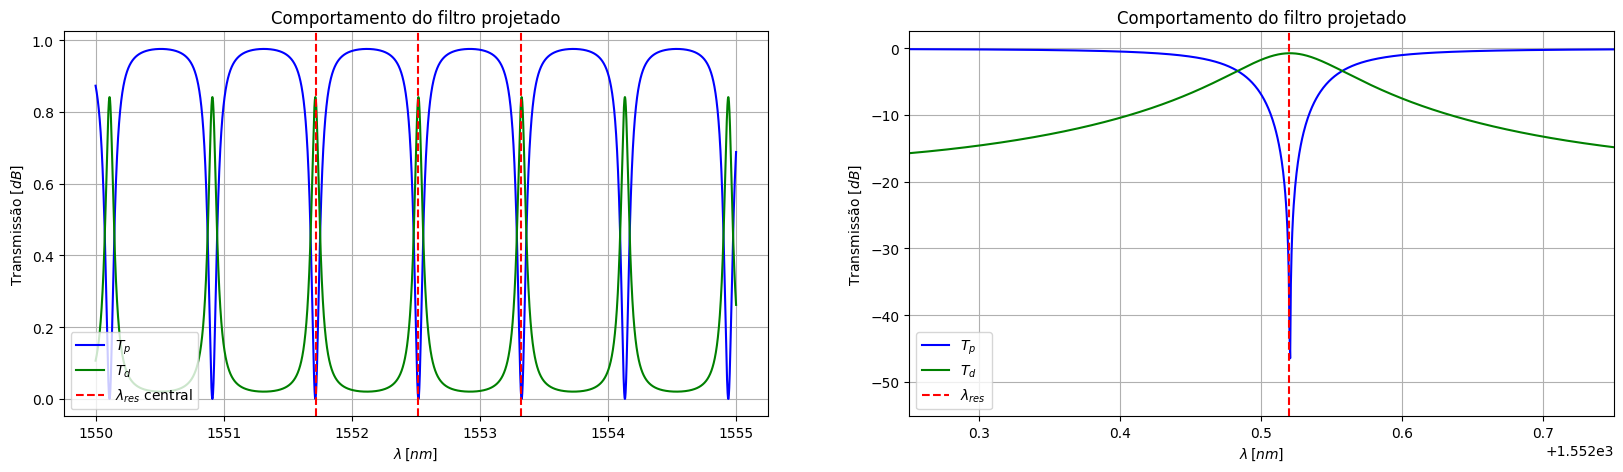

In [57]:
L = 714.398*um # Com ajustes finos
a = 0.9756
r1 = 0.8548
r2 = 0.8762

lambda_array = np.linspace(1550*nm, 1555*nm, 10001)

phi_array = phi(lambda_array, L, neff)
Tp_array = T_p(phi_array, r1, r2, a)
Td_array = T_d(phi_array, r1, r2, a)

Tp_dB_array = 10*np.log10(Tp_array)
Td_dB_array = 10*np.log10(Td_array)

fig, ax = plt.subplots(1,2, figsize = (20,5))

ax[0].plot(lambda_array/nm, Tp_array, color = 'blue', label = '$T_p$')
ax[0].plot(lambda_array/nm, Td_array, color = 'green', label = r'$T_d$')
ax[0].axvline(1552.52-0.8, linestyle = '--', color = 'red', label = r'$\lambda_{res}$ central')
ax[0].axvline(1552.52, linestyle = '--', color = 'red')
ax[0].axvline(1552.52+0.8, linestyle = '--', color = 'red')
ax[0].grid(True)
ax[0].set_xlabel(r'$\lambda\,[nm]$')
ax[0].set_ylabel(r'Transmissão [$dB$]')
ax[0].legend(loc = 'lower left')
ax[0].set_title('Comportamento do filtro projetado')

ax[1].plot(lambda_array/nm, Tp_dB_array, color = 'blue', label = '$T_p$')
ax[1].plot(lambda_array/nm, Td_dB_array, color = 'green', label = r'$T_d$')
ax[1].axvline(1552.52, linestyle = '--', color = 'red', label = r'$\lambda_{res}$')
#ax[1].axhline(-3, linestyle = '--', color = 'black', label = r'$-3\,dB$')
ax[1].grid(True)
ax[1].set_xlabel(r'$\lambda\,[nm]$')
ax[1].set_ylabel(r'Transmissão [$dB$]')
ax[1].legend(loc = 'lower left')
ax[1].set_title('Comportamento do filtro projetado')
ax[1].set_xlim([1552.25, 1552.75])

plt.show()

### Resposta da 2 ###

Considerando os acopladores simétricos, para $T_{d,max}>0,5$:

$$r=\sqrt{\frac{x}{a}}\,,\, x\approx 0,9391\,;$$

$$a<0,9818\,;$$

Como $L=714,398\,\mu m$:

$$\alpha_{dB}\approx 2,23\,dB/cm\,.$$

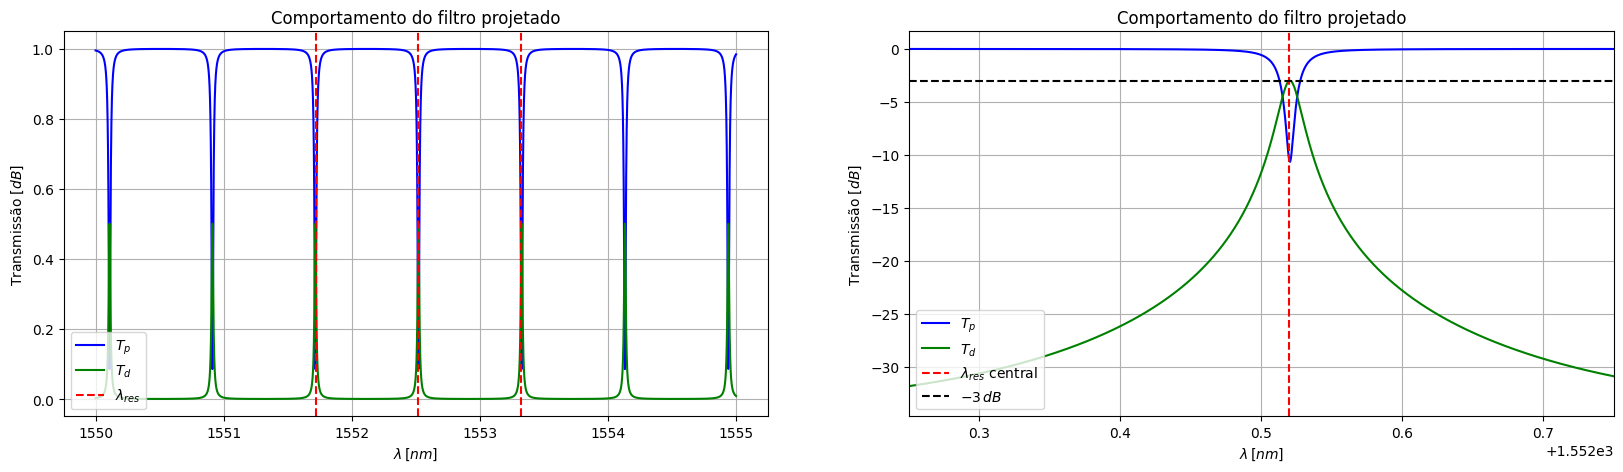

In [58]:
a = 0.9818
x = 0.9391
r = np.sqrt(x/a)

phi_array = phi(lambda_array, L, neff)
Tp_array = T_p(phi_array, r, r, a)
Td_array = T_d(phi_array, r, r, a)

Tp_dB_array = 10*np.log10(Tp_array)
Td_dB_array = 10*np.log10(Td_array)

fig, ax = plt.subplots(1,2, figsize = (20,5))

ax[0].plot(lambda_array/nm, Tp_array, color = 'blue', label = '$T_p$')
ax[0].plot(lambda_array/nm, Td_array, color = 'green', label = r'$T_d$')
ax[0].axvline(1552.52-0.8, linestyle = '--', color = 'red', label = r'$\lambda_{res}$')
ax[0].axvline(1552.52, linestyle = '--', color = 'red')
ax[0].axvline(1552.52+0.8, linestyle = '--', color = 'red')
ax[0].grid(True)
ax[0].set_xlabel(r'$\lambda\,[nm]$')
ax[0].set_ylabel(r'Transmissão [$dB$]')
ax[0].legend(loc = 'lower left')
ax[0].set_title('Comportamento do filtro projetado')

ax[1].plot(lambda_array/nm, Tp_dB_array, color = 'blue', label = '$T_p$')
ax[1].plot(lambda_array/nm, Td_dB_array, color = 'green', label = r'$T_d$')
ax[1].axvline(1552.52, linestyle = '--', color = 'red', label = r'$\lambda_{res}$ central')
ax[1].axhline(-3, linestyle = '--', color = 'black', label = r'$-3\,dB$')
ax[1].grid(True)
ax[1].set_xlabel(r'$\lambda\,[nm]$')
ax[1].set_ylabel(r'Transmissão [$dB$]')
ax[1].legend(loc = 'lower left')
ax[1].set_title('Comportamento do filtro projetado')
ax[1].set_xlim([1552.25, 1552.75])

plt.show()

### Resposta da 4 ###

Nesse projeto:

$$L_1\approx79,23\,\mu m\,,\,L_2\approx 95,07\,\mu m\,;$$

$$FSR_1\approx 7,235\,nm\,,\,FSR_2\approx 6,030\,nm$$

$$a_1\approx 0,9973\,,\,a_2\approx 0,9967\,.$$

$$r_1\approx 0,9588\,,\,r_2\approx 0,9508\,;$$

$$ER=-21,65\,dB\,.$$

Para manter a supressão em $-25\,dB$ é necessária uma $FWHM$ de:

$$FWHM\approx 0,13\,nm\,,$$

o que fica em:

$$Q\approx 11923\,.$$

In [59]:
L1 = 79.23*um
L2 = 95.07*um

a1 = 0.9973
a2 = 0.9967

r1 = 0.9669
r2 = 0.9587

lambda_array = np.linspace(1500, 1600, 5001)*nm

phi_array1 = phi(lambda_array, L1)
phi_array2 = phi(lambda_array, L2)

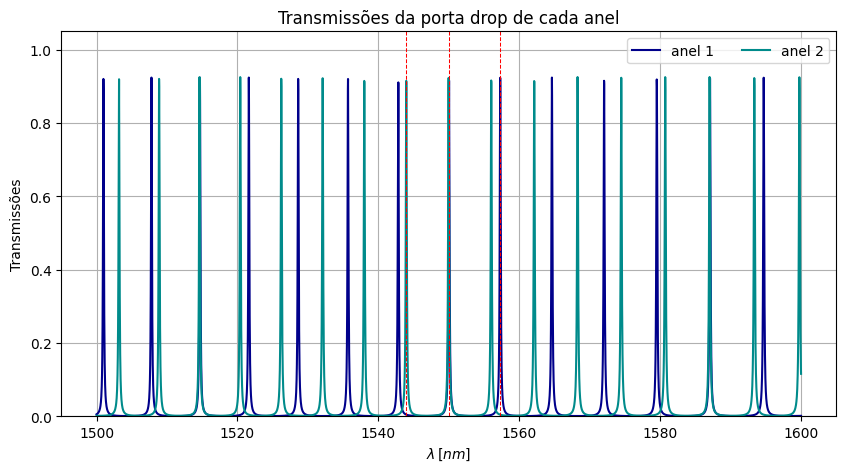

In [62]:
Td1 = T_d(phi_array1, r1, r1, a1)
Td2 = T_d(phi_array2, r2, r2, a2)


plt.figure(figsize = (10,5))
plt.plot(lambda_array/nm, Td1, color = 'darkblue', label = 'anel 1')
plt.plot(lambda_array/nm, Td2, color = 'darkcyan', label = 'anel 2')
plt.grid(True)
plt.legend(loc = 'upper right', ncols = 2)
plt.xlabel(r'$\lambda\,[nm]$')
plt.ylabel(r'Transmissões')
plt.title('Transmissões da porta drop de cada anel')
plt.ylim([0, 1.05])
plt.axvline(1550, color = 'red', linestyle = '--', linewidth = 0.75)
plt.axvline(1550+7.235, color = 'red', linestyle = '--', linewidth = 0.75)
plt.axvline(1550-6.030, color = 'red', linestyle = '--', linewidth = 0.75)
plt.show()

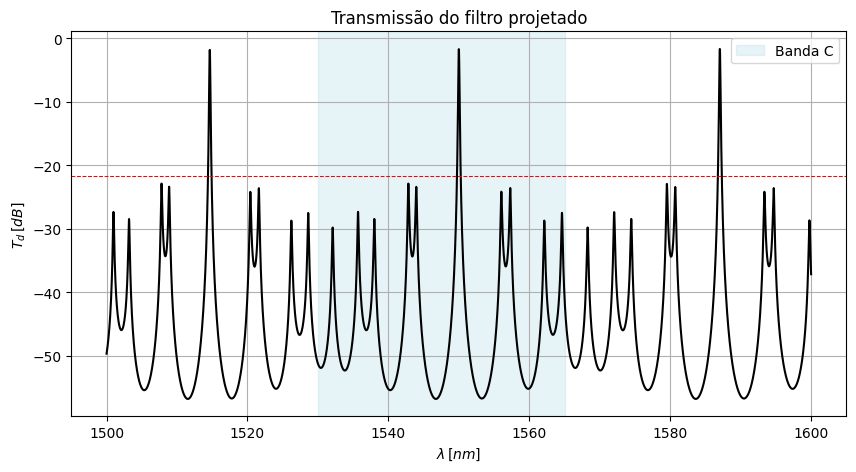

In [67]:
Td = Td1*Td2

plt.figure(figsize = (10,5))
plt.plot(lambda_array/nm, 10*np.log10(Td), color = 'black')
#plt.plot(lambda_array/nm, Td, color = 'black')
plt.grid(True)
plt.xlabel(r'$\lambda\,[nm]$')
plt.ylabel(r'$T_d\,[dB]$')
plt.title('Transmissão do filtro projetado')
plt.axvspan(1530, 1565, color = 'lightblue', alpha = 0.3, label = 'Banda C')
#plt.axvline(1550, color = 'red', linestyle = '--', linewidth = 0.75)
#plt.axvline(1550+36.9, color = 'red', linestyle = '--', linewidth = 0.75)
#plt.axvline(1550-35.5, color = 'red', linestyle = '--', linewidth = 0.75)
plt.axhline(-21.65, color = 'red', linestyle = '--', linewidth = 0.75)
plt.legend(loc = 'upper right')
plt.show()